# Airbnb NYC 2019 — Final Data Analysis Project

**Dataset constraint:** This project uses only the supplied `AB_NYC_2019.csv` file. No external datasets are added.

## Project goal
Understand the NYC Airbnb listing market, prepare the supplied data, explore listing types, neighborhood differences, prices, reviews, and availability, then derive evidence-based recommendations.

> The file describes Airbnb listings in New York City in 2019. Price is the listed nightly price as recorded in this dataset; results should not be interpreted as current 2026 prices or as actual booking revenue.


## 1. Data Understanding

Key questions:
- Which room types and boroughs contain the most listings?
- How do listed prices vary by borough and room type?
- How are prices distributed, and how prominent are extreme values?
- What relationships appear between price, reviews, minimum nights, and availability?
- Which neighborhoods have high listing counts or high median prices?

Main fields include `neighbourhood_group`, `neighbourhood`, `room_type`, `price`, `minimum_nights`, `number_of_reviews`, `last_review`, `reviews_per_month`, and `availability_365`.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("AB_NYC_2019.csv")
print("Shape:", df.shape)
display(df.head())
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_count", ascending=False))
print("Duplicate rows:", df.duplicated().sum())


Shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


,dtype,missing_count,missing_pct,unique_values
last_review,object,10052,20.56,1764
reviews_per_month,float64,10052,20.56,937
host_name,object,21,0.04,11452
name,object,16,0.03,47905
neighbourhood_group,object,0,0.00,5
neighbourhood,object,0,0.00,221
id,int64,0,0.00,48895
host_id,int64,0,0.00,37457
longitude,float64,0,0.00,14718
latitude,float64,0,0.00,19048


Duplicate rows: 0


## 2. Data Cleaning & Preparation

Cleaning choices:
- Check duplicates before removing anything.
- Trim whitespace in text/categorical fields.
- Fill missing listing names and host names with `Unknown`; these are descriptive fields.
- Convert `last_review` to a date type; keep missing dates missing because no review history is meaningful.
- Fill `reviews_per_month` with 0 only where `number_of_reviews == 0` and the monthly-review value is missing. This matches the structure of the supplied data.
- Keep unusual price and minimum-night values in the dataset, but add flags. Extreme values may be genuine listings and should be investigated before exclusion.
- Flag zero-price listings for review rather than silently deleting them.


In [10]:
clean = df.copy()

text_cols = [
    "name",
    "host_name",
    "neighbourhood_group",
    "neighbourhood",
    "room_type"
]

for col in text_cols:
    clean[col] = (
        clean[col]
        .astype("string")
        .str.replace(r"[\r\n\t]+", " ", regex=True)
        .str.replace(r"\s{2,}", " ", regex=True)
        .str.strip()
    )


clean["name"] = clean["name"].fillna("Unknown")
clean["host_name"] = clean["host_name"].fillna("Unknown")


clean["last_review"] = pd.to_datetime(
    clean["last_review"],
    errors="coerce"
)

no_reviews = clean["number_of_reviews"].eq(0)

clean.loc[
    no_reviews & clean["reviews_per_month"].isna(),
    "reviews_per_month"
] = 0

q1, q3 = clean["price"].quantile([0.25, 0.75])
iqr = q3 - q1
price_upper_fence = q3 + 1.5 * iqr

nq1, nq3 = clean["minimum_nights"].quantile([0.25, 0.75])
niqr = nq3 - nq1
minimum_nights_upper_fence = nq3 + 1.5 * niqr

clean["is_zero_price"] = clean["price"].eq(0)

clean["price_outlier_iqr"] = (
    clean["price"] > price_upper_fence
)

clean["minimum_nights_outlier_iqr"] = (
    clean["minimum_nights"] > minimum_nights_upper_fence
)


print("Cleaned shape:", clean.shape)
print("Duplicate rows:", clean.duplicated().sum())

print("\nMissing values after cleaning:")
display(
    clean.isna().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\nZero-price listings:", int(clean["is_zero_price"].sum()))
print("Price IQR outliers:", int(clean["price_outlier_iqr"].sum()))
print(
    "Minimum-night IQR outliers:",
    int(clean["minimum_nights_outlier_iqr"].sum())
)

for col in text_cols:
    assert not clean[col].str.contains(
        r"[\r\n\t]", regex=True, na=False
    ).any(), f"Line breaks still exist in {col}"

print("\nText-column validation passed.")


Cleaned shape: (48895, 19)
Duplicate rows: 0

Missing values after cleaning:


,missing_count
last_review,10052
name,0
id,0
host_id,0
host_name,0
neighbourhood,0
neighbourhood_group,0
longitude,0
room_type,0
price,0



Zero-price listings: 11
Price IQR outliers: 2972
Minimum-night IQR outliers: 6607

Text-column validation passed.


## 3. Exploratory Data Analysis (EDA)

The charts below are designed to answer specific business questions. Interpret results as patterns/associations, not proof of causation.


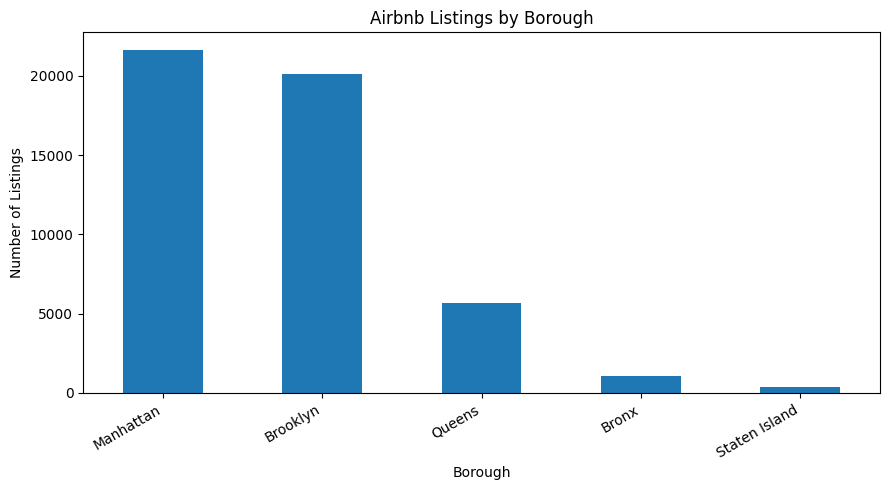

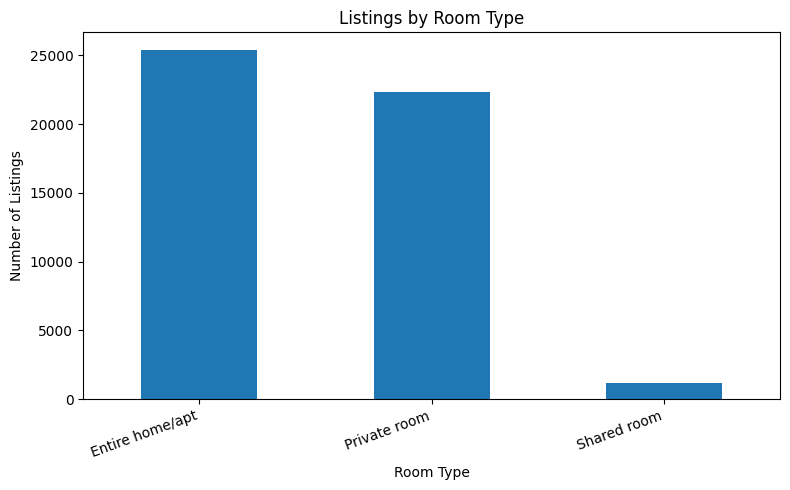

In [11]:
borough_counts = clean["neighbourhood_group"].value_counts()
plt.figure(figsize=(9, 5))
borough_counts.plot(kind="bar")
plt.title("Airbnb Listings by Borough")
plt.xlabel("Borough")
plt.ylabel("Number of Listings")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

room_counts = clean["room_type"].value_counts()
plt.figure(figsize=(8, 5))
room_counts.plot(kind="bar")
plt.title("Listings by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


Price quantiles:


,price
0.500,106.0
0.750,175.0
0.900,269.0
0.950,355.0
0.990,799.0
0.995,1000.0
0.999,3000.0


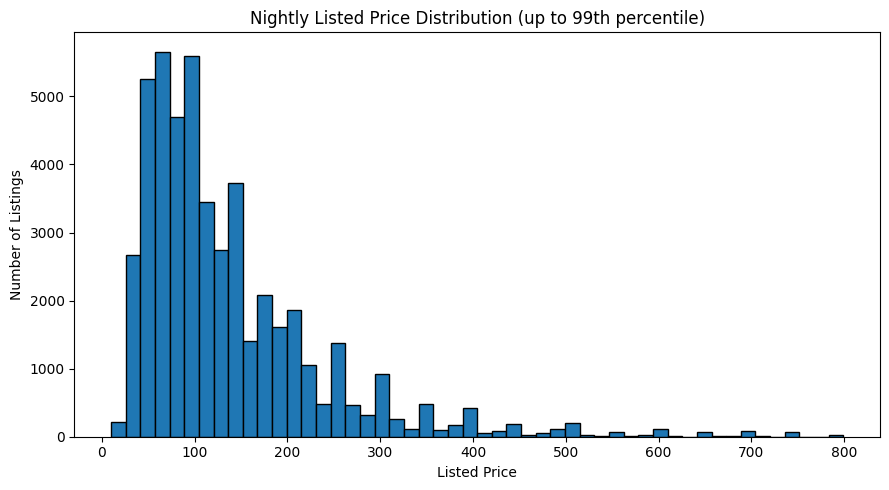

,median_price
neighbourhood_group,
Manhattan,150.0
Brooklyn,90.0
Queens,75.0
Staten Island,75.0
Bronx,65.0


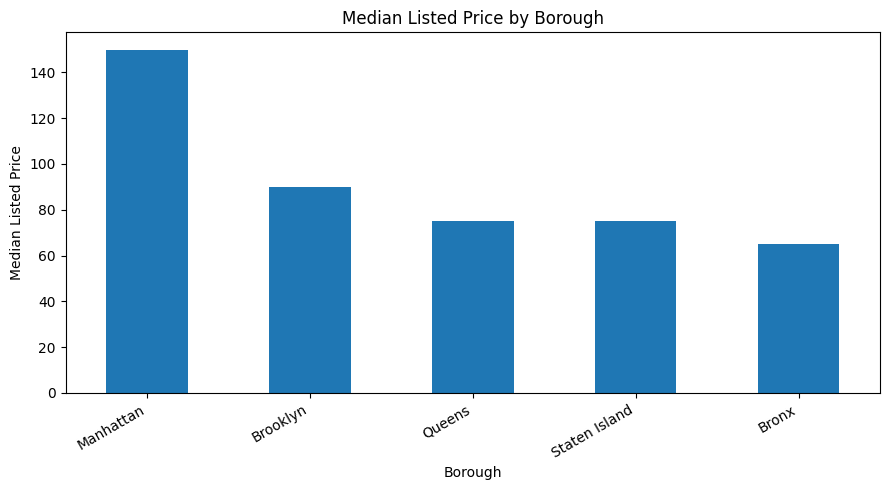

In [12]:
# Price distribution: raw and trimmed view for readability
print("Price quantiles:")
display(clean["price"].quantile([.50, .75, .90, .95, .99, .995, .999]).to_frame("price"))

plt.figure(figsize=(9, 5))
clean.loc[clean["price"].between(1, clean["price"].quantile(.99)), "price"].plot(
    kind="hist", bins=50, edgecolor="black"
)
plt.title("Nightly Listed Price Distribution (up to 99th percentile)")
plt.xlabel("Listed Price")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

borough_price = clean.groupby("neighbourhood_group")["price"].median().sort_values(ascending=False)
display(borough_price.to_frame("median_price"))
plt.figure(figsize=(9, 5))
borough_price.plot(kind="bar")
plt.title("Median Listed Price by Borough")
plt.xlabel("Borough")
plt.ylabel("Median Listed Price")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


,count,mean,median
room_type,,,
Entire home/apt,25409,211.79,160.0
Private room,22326,89.78,70.0
Shared room,1160,70.13,45.0


<Figure size 900x500 with 0 Axes>

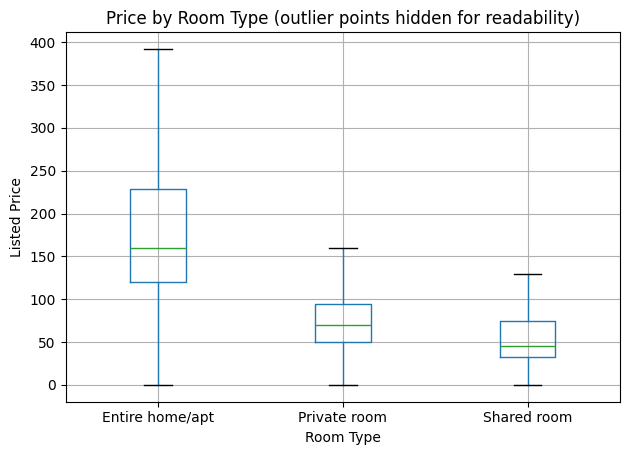

In [13]:
# Room type versus price
room_price = clean.groupby("room_type")["price"].agg(["count", "mean", "median"]).sort_values("median", ascending=False)
display(room_price.round(2))
plt.figure(figsize=(9, 5))
clean.boxplot(column="price", by="room_type", showfliers=False)
plt.title("Price by Room Type (outlier points hidden for readability)")
plt.suptitle("")
plt.xlabel("Room Type")
plt.ylabel("Listed Price")
plt.tight_layout()
plt.show()


,price,number_of_reviews,reviews_per_month,minimum_nights,availability_365,calculated_host_listings_count
price,1.000,-0.048,-0.051,0.043,0.082,0.057
number_of_reviews,-0.048,1.000,0.589,-0.080,0.172,-0.072
reviews_per_month,-0.051,0.589,1.000,-0.125,0.164,-0.047
minimum_nights,0.043,-0.080,-0.125,1.000,0.144,0.128
availability_365,0.082,0.172,0.164,0.144,1.000,0.226
calculated_host_listings_count,0.057,-0.072,-0.047,0.128,0.226,1.000


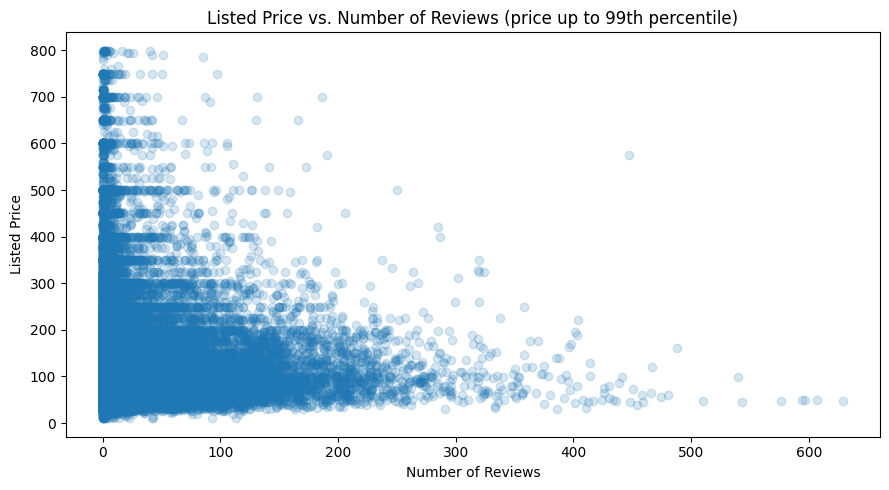

In [14]:
numeric_cols = [
    "price", "number_of_reviews", "reviews_per_month", "minimum_nights",
    "availability_365", "calculated_host_listings_count"
]
display(clean[numeric_cols].corr(numeric_only=True).round(3))

sample = clean.loc[
    clean["price"].between(1, clean["price"].quantile(.99)) &
    clean["number_of_reviews"].ge(0)
]
plt.figure(figsize=(9, 5))
plt.scatter(sample["number_of_reviews"], sample["price"], alpha=0.18)
plt.title("Listed Price vs. Number of Reviews (price up to 99th percentile)")
plt.xlabel("Number of Reviews")
plt.ylabel("Listed Price")
plt.tight_layout()
plt.show()


,listing_count
neighbourhood,
Williamsburg,3920
Bedford-Stuyvesant,3714
Harlem,2658
Bushwick,2465
Upper West Side,1971
Hell's Kitchen,1958
East Village,1853
Upper East Side,1798
Crown Heights,1564


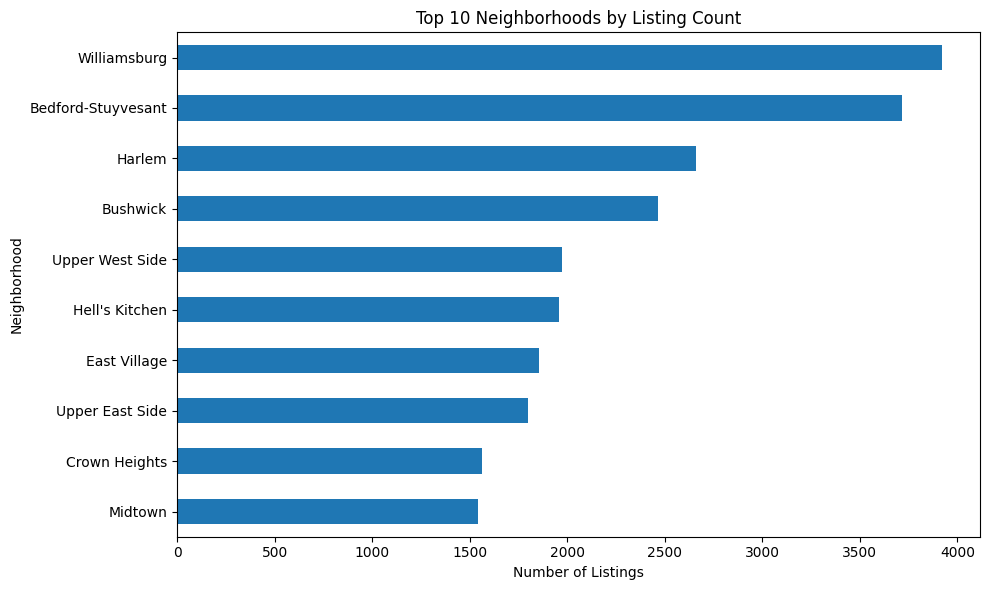

,count,median,mean
neighbourhood,,,
Tribeca,177,295.0,490.64
Midtown,1545,210.0,282.72
Financial District,744,200.0,225.49
West Village,768,200.0,267.68
SoHo,358,199.0,287.10
Chelsea,1113,199.0,249.74
Greenwich Village,392,197.5,263.41
Murray Hill,485,190.0,220.96
Theater District,288,190.0,248.01


In [15]:
top_neighborhoods = clean["neighbourhood"].value_counts().head(10)
display(top_neighborhoods.to_frame("listing_count"))
plt.figure(figsize=(10, 6))
top_neighborhoods.sort_values().plot(kind="barh")
plt.title("Top 10 Neighborhoods by Listing Count")
plt.xlabel("Number of Listings")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()

neighborhood_price = clean.groupby("neighbourhood")["price"].agg(["count", "median", "mean"])
neighborhood_price = neighborhood_price[neighborhood_price["count"] >= 100]
display(neighborhood_price.sort_values("median", ascending=False).head(15).round(2))


## 4. Initial Business Insights & Recommendations

Use the measured results from the preceding cells to refine these initial directions:
- Concentration: compare listing volume across boroughs and high-volume neighborhoods; market saturation and demand cannot be inferred from listing count alone.
- Pricing: compare median prices by borough and room type. Use medians as well as means because high-priced outliers can inflate averages.
- Review activity: check the relationship between reviews and price; reviews are not the same as occupancy or revenue.
- Data quality: investigate zero-price and extreme-price listings before deciding whether they should be excluded from any particular chart.
- Availability: `availability_365` measures days listed as available in the dataset, not confirmed bookings or occupancy.

## 5. Export Cleaned Dataset

Run this cell to export the cleaned file.


In [16]:
clean.to_csv("AB_NYC_2019_Cleaned.csv", index=False)
print("Saved: AB_NYC_2019_Cleaned.csv")


Saved: AB_NYC_2019_Cleaned.csv
